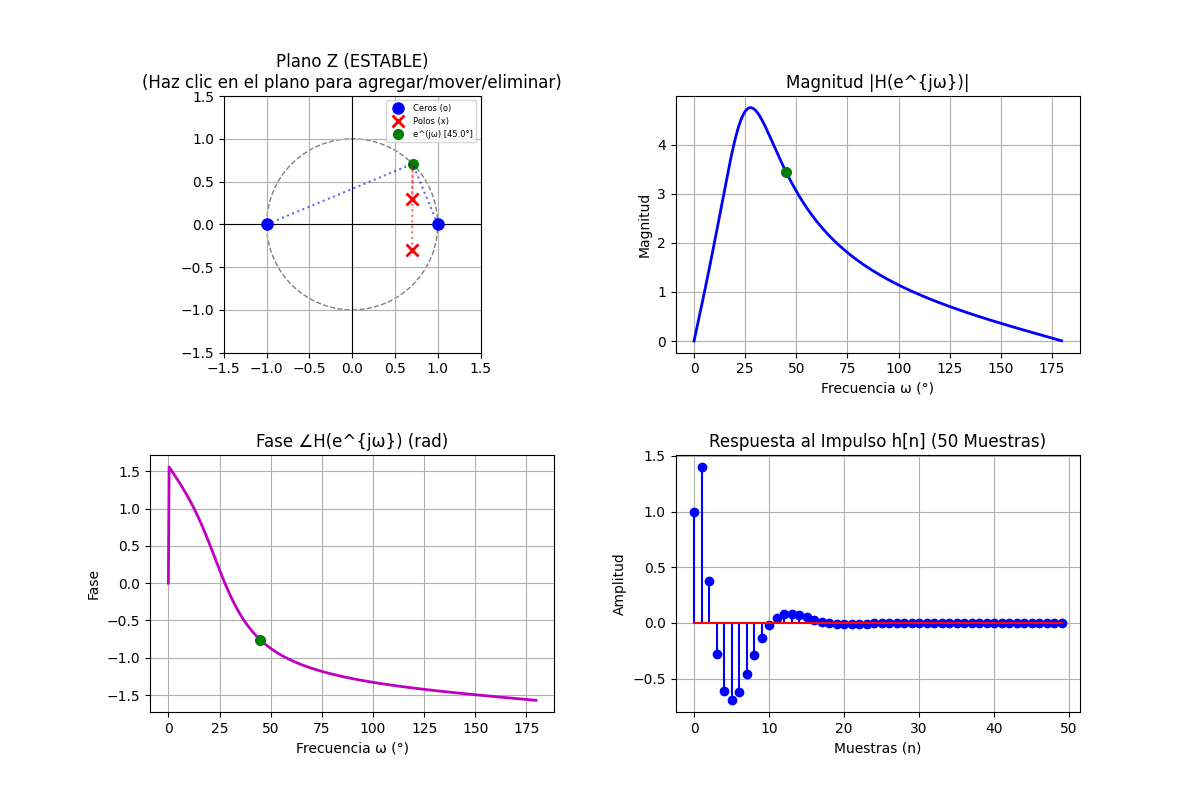

In [5]:
# 1. Instalar el paquete interactivo para Colab
!pip install -q ipympl

# 2. Habilitar el manejador de widgets personalizados en Google Colab
from google.colab import output
output.enable_custom_widget_manager()

# 3. Activar el backend interactivo
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import ipywidgets as widgets
from IPython.display import display

TOL_CU = 1e-3   # Tolerancia para considerar que un polo está SOBRE el círculo unitario

class ZPlaneInteractive:
    def __init__(self):
        # Polos y ceros iniciales por defecto (ej. diseño pasa-bajas)
        self.poles = [0.7 + 0.3j, 0.7 - 0.3j]
        self.zeros = [1.0 + 0.0j, -1.0 + 0.0j]
        self.K = 1.0
        self.w_eval_deg = 45.0
        self.mode = "Polo" # Modos: "Polo", "Cero", "Mover", "Eliminar"
        self.drag = None   # Raíz que se está arrastrando en modo "Mover"

        # Crear figura y subplots
        self.fig, self.axs = plt.subplots(2, 2, figsize=(12, 8))
        plt.subplots_adjust(hspace=0.4, wspace=0.3)

        # Conectar los eventos del mouse (clic, arrastre y soltar)
        self.fig.canvas.mpl_connect('button_press_event', self.on_click)
        self.fig.canvas.mpl_connect('motion_notify_event', self.on_motion)
        self.fig.canvas.mpl_connect('button_release_event', self.on_release)

        # Inicializar los widgets de control y el panel de texto para H(z)
        self.init_widgets()

        # Dibujar por primera vez
        self.update_plots()

    def init_widgets(self):
        self.mode_radio = widgets.RadioButtons(
            options=['Polo (x)', 'Cero (o)', 'Mover raíz', 'Eliminar raíz'],
            value='Polo (x)',
            description='Acción:',
            disabled=False
        )
        self.mode_radio.observe(self.on_mode_change, names='value')

        self.k_slider = widgets.FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1, description='Ganancia K:')
        self.k_slider.observe(self.on_k_change, names='value')

        self.w_slider = widgets.FloatSlider(value=45.0, min=0.0, max=180.0, step=5.0, description='Eval ω°:')
        self.w_slider.observe(self.on_w_change, names='value')

        # Widget de texto HTML para mostrar la función de transferencia en tiempo real
        self.tf_output = widgets.HTML(
            value="<b>Función de Transferencia H(z):</b> Calculando..."
        )

        # Agrupar interfaz completa de widgets
        self.ui = widgets.VBox([
            widgets.HBox([self.mode_radio, self.k_slider]),
            self.w_slider,
            widgets.HTML("<hr>"),
            self.tf_output
        ])

    def on_mode_change(self, change):
        val = change['new']
        if 'Polo' in val: self.mode = "Polo"
        elif 'Cero' in val: self.mode = "Cero"
        elif 'Mover' in val: self.mode = "Mover"
        else: self.mode = "Eliminar"

    def on_k_change(self, change):
        self.K = change['new']
        self.update_plots()

    def on_w_change(self, change):
        self.w_eval_deg = change['new']
        self.update_plots()

    # ---------- Modo "Mover": localizar la raíz más cercana y su conjugada ----------
    def _raiz_cercana(self, click_pos, umbral=0.15):
        mejor = None
        for tipo, lista in (('polo', self.poles), ('cero', self.zeros)):
            for i, r in enumerate(lista):
                d = abs(r - click_pos)
                if d < umbral and (mejor is None or d < mejor[0]):
                    mejor = (d, tipo, i)
        if mejor is None:
            return None
        _, tipo, i = mejor
        lista = self.poles if tipo == 'polo' else self.zeros
        r = lista[i]
        j = None
        if abs(r.imag) > 1e-4:   # raíz compleja: buscar el índice de su conjugada
            cands = [k for k in range(len(lista)) if k != i]
            if cands:
                j = min(cands, key=lambda k: abs(lista[k] - np.conj(r)))
        return {'tipo': tipo, 'i': i, 'j': j}

    def on_click(self, event):
        # Verificar que el clic ocurra estrictamente dentro del primer subplot (Plano Z)
        if event.inaxes != self.axs[0, 0] or event.xdata is None or event.ydata is None:
            return

        click_pos = event.xdata + 1j * event.ydata

        if self.mode == "Polo":
            self.poles.append(click_pos)
            if abs(click_pos.imag) > 1e-4:
                self.poles.append(np.conj(click_pos))

        elif self.mode == "Cero":
            self.zeros.append(click_pos)
            if abs(click_pos.imag) > 1e-4:
                self.zeros.append(np.conj(click_pos))

        elif self.mode == "Mover":
            self.drag = self._raiz_cercana(click_pos)
            return

        elif self.mode == "Eliminar":
            all_roots = self.poles + self.zeros
            if all_roots:
                distances = [abs(r - click_pos) for r in all_roots]
                min_idx = np.argmin(distances)
                if min_idx < len(self.poles):
                    p_rem = self.poles.pop(min_idx)
                    self.poles = [p for p in self.poles if abs(p - np.conj(p_rem)) > 1e-2]
                else:
                    z_rem = self.zeros.pop(min_idx - len(self.poles))
                    self.zeros = [z for z in self.zeros if abs(z - np.conj(z_rem)) > 1e-2]

        self.update_plots()

    def on_motion(self, event):
        if self.drag is None or event.inaxes != self.axs[0, 0] or event.xdata is None:
            return
        lista = self.poles if self.drag['tipo'] == 'polo' else self.zeros
        if self.drag['j'] is None:
            # Raíz real: se desplaza sobre el eje real para mantener coeficientes reales
            lista[self.drag['i']] = complex(event.xdata, 0.0)
        else:
            # Par complejo: se mueve la raíz y su conjugada juntas
            nueva = complex(event.xdata, event.ydata)
            lista[self.drag['i']] = nueva
            lista[self.drag['j']] = np.conj(nueva)
        self.update_plots()

    def on_release(self, event):
        self.drag = None

    def update_plots(self):
        for ax_row in self.axs:
            for ax in ax_row:
                ax.clear()

        p_arr = np.array(self.poles) if self.poles else np.array([])
        z_arr = np.array(self.zeros) if self.zeros else np.array([])
        M, N = len(z_arr), len(p_arr)   # número de ceros y de polos

        # Obtener función de transferencia (polinomios en potencias positivas de z)
        try:
            b, a = signal.zpk2tf(z_arr, p_arr, self.K)
            b, a = np.real(np.atleast_1d(b)), np.real(np.atleast_1d(a))
        except Exception:
            b, a = np.array([1.0]), np.array([1.0])

        # Actualizar texto de la Función de Transferencia en pantalla
        zeros_text = " · ".join([f"(z - ({z.real:.2f}{z.imag:+.2f}j))" for z in z_arr]) if len(z_arr) > 0 else "1"
        poles_text = " · ".join([f"(z - ({p.real:.2f}{p.imag:+.2f}j))" for p in p_arr]) if len(p_arr) > 0 else "1"

        tf_html = f"""
        <div style="font-family: monospace; font-size: 13px; background-color: #f4f6f7; padding: 10px; border-radius: 5px; border: 1px solid #d5dbdb;">
            <b>📋 FUNCIÓN DE TRANSFERENCIA H(z):</b><br><br>
            <b>Forma Factorizada:</b><br>
            &nbsp;&nbsp;&nbsp;&nbsp;H(z) = {self.K:.2f} · [ {zeros_text} ] / [ {poles_text} ]<br><br>
            <b>Coeficientes del Numerador (b):</b><br>
            &nbsp;&nbsp;&nbsp;&nbsp;{np.round(b, 4).tolist()}<br><br>
            <b>Coeficientes del Denominador (a):</b><br>
            &nbsp;&nbsp;&nbsp;&nbsp;{np.round(a, 4).tolist()}
        </div>
        """
        self.tf_output.value = tf_html

        # Verificación de estabilidad (sistema causal)
        if N > 0:
            radios = np.abs(p_arr)
            if np.all(radios < 1.0 - TOL_CU):
                estado_est = "ESTABLE"
            elif np.any(radios > 1.0 + TOL_CU):
                estado_est = "INESTABLE"
            else:
                estado_est = "MARGINALMENTE ESTABLE (polo sobre |z|=1)"
        else:
            estado_est = "ESTABLE (Sin polos)"

        # --- 1. Plano Z ---
        ax1 = self.axs[0, 0]
        uc = plt.Circle((0, 0), 1, color='gray', fill=False, linestyle='--')
        ax1.add_patch(uc)
        ax1.axhline(0, color='black', lw=0.8)
        ax1.axvline(0, color='black', lw=0.8)

        if len(z_arr) > 0:
            ax1.plot(np.real(z_arr), np.imag(z_arr), 'ob', markersize=8, label='Ceros (o)')
        if len(p_arr) > 0:
            ax1.plot(np.real(p_arr), np.imag(p_arr), 'xr', markersize=9, markeredgewidth=2, label='Polos (x)')

        w_eval = np.radians(self.w_eval_deg)
        z_eval = np.exp(1j * w_eval)
        ax1.plot(np.real(z_eval), np.imag(z_eval), 'go', markersize=7, label=f'e^(jω) [{self.w_eval_deg:.1f}°]')

        # Distancias geométricas
        for z in z_arr:
            ax1.plot([np.real(z), np.real(z_eval)], [np.imag(z), np.imag(z_eval)], 'b:', alpha=0.6)
        for p in p_arr:
            ax1.plot([np.real(p), np.real(z_eval)], [np.imag(p), np.imag(z_eval)], 'r:', alpha=0.6)

        ax1.set_xlim([-1.5, 1.5])
        ax1.set_ylim([-1.5, 1.5])
        ax1.set_aspect('equal')
        ax1.set_title(f'Plano Z ({estado_est})\n(Haz clic en el plano para agregar/mover/eliminar)')
        ax1.legend(loc='upper right', fontsize=6)
        ax1.grid(True)

        # --- 2. Respuesta en Frecuencia: H(e^{jω}) = H(z)|z=e^{jω} evaluada directamente
        #        con la forma factorizada K·∏(z - z_i)/∏(z - p_k)
        with np.errstate(divide='ignore', invalid='ignore'):
            w, h = signal.freqz_zpk(z_arr, p_arr, self.K, worN=512)
            _, h_point = signal.freqz_zpk(z_arr, p_arr, self.K, worN=[w_eval])
        h = np.where(np.isfinite(h), h, np.nan)             # puntos indefinidos (polo en e^{jω}) -> hueco
        h_point = np.where(np.isfinite(h_point), h_point, np.nan)
        w_deg = np.degrees(w)
        mag = np.abs(h)

        ax2 = self.axs[0, 1]
        ax2.plot(w_deg, mag, 'b-', lw=2)
        mag_point = np.abs(h_point[0])
        if np.isfinite(mag_point):
            ax2.plot(self.w_eval_deg, mag_point, 'go', markersize=7)
        else:
            ax2.axvline(self.w_eval_deg, color='g', ls='--')
            ax2.text(0.5, 0.9, '|H| no definida: polo sobre e^{jω}', color='red',
                     ha='center', transform=ax2.transAxes, fontsize=8)
        ax2.set_title('Magnitud |H(e^{jω})|')
        ax2.set_xlabel('Frecuencia ω (°)')
        ax2.set_ylabel('Magnitud')
        ax2.grid(True)

        # --- 3. Respuesta en Frecuencia (Fase) ---
        phase = np.angle(h)
        ax3 = self.axs[1, 0]
        ax3.plot(w_deg, phase, 'm-', lw=2)
        if np.isfinite(mag_point):
            ax3.plot(self.w_eval_deg, np.angle(h_point[0]), 'go', markersize=7)
        ax3.set_title('Fase ∠H(e^{jω}) (rad)')
        ax3.set_xlabel('Frecuencia ω (°)')
        ax3.set_ylabel('Fase')
        ax3.grid(True)

        # --- 4. Respuesta al Impulso h[n] (sistema causal, condiciones iniciales nulas) ---
        n_samples = 50
        n = np.arange(n_samples)
        impulse = np.zeros(n_samples)
        impulse[0] = 1.0
        ax4 = self.axs[1, 1]

        if M <= N:
            # lfilter interpreta b y a en potencias de z^{-1}: se rellenan con ceros a la
            # izquierda para que ambos tengan grado N y h[n] corresponda a la H(z) mostrada
            b_c = np.concatenate([np.zeros(N - M), b])
            h_impulse = signal.lfilter(b_c, a, impulse)
            ax4.stem(n, h_impulse, linefmt='b-', markerfmt='bo', basefmt='r-')
        else:
            ax4.text(0.5, 0.5, 'H(z) no causal: hay más ceros que polos\n(agrega polos para M ≤ N)',
                     ha='center', va='center', color='red', transform=ax4.transAxes)
        ax4.set_title('Respuesta al Impulso h[n] (50 Muestras)')
        ax4.set_xlabel('Muestras (n)')
        ax4.set_ylabel('Amplitud')
        ax4.grid(True)

        self.fig.canvas.draw_idle()

# Ejecutar la aplicación interactiva con clics y visualización de H(z)
app = ZPlaneInteractive()
display(app.ui)

In [16]:
import numpy as np
r = 1.05         # cambia: 0.5, 0.9, 0.99, 1.0, 1.05
th = np.radians(45)
app.zeros = []
app.poles = [r*np.exp(1j*th), r*np.exp(-1j*th)]
app.update_plots()